# 02 - Ontology

Builds the ontology from section 7 of [`01_data_eda.ipynb`](01_data_eda.ipynb) as an OWL file
(`data/ontology/adult.owl`, opens in Protege), checks that every model feature maps to one concept per level, and
reports the information content (IC) of each concept.

Choices from the EDA applied in `preprocess.encode`:
- `fnlwgt` is dropped from the model inputs (`preprocess.EXCLUDED`): sampling weight, outside the ontology.
- rows with missing `workclass` / `occupation` / `native-country` stay; NaN becomes all-zero dummies.
- `education` and `education-num` both stay; they share the `EducationLevel` concept.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from project_acl import ontology
from project_acl.preprocess import EXCLUDED, encode, read

sns.set_theme(style="white", context="notebook")
FIG = Path("../docs/figures")
FIG.mkdir(exist_ok=True)

path = ontology.build()
onto = ontology.load(path)  # reload from disk: the checks below read the saved file
print(path.relative_to(path.parents[2]), "|", len(list(onto.classes())), "classes")
# concepts ordered by depth: root, top concepts, leaves
for c in sorted(onto.Person.descendants(), key=lambda c: (len(c.ancestors()), c.name)):
    print(f"{c.name:15s} parent={c.is_a[0].name:13s} features={list(c.mapsToFeature)}")
print(f"{onto.ProtectedAttribute.name:15s} (separate view)   features={list(onto.ProtectedAttribute.mapsToFeature)}")

[16:29:10] INFO     saved ontology /home/aprofir/uni/ACL/project/data/ontology/adult.owl             ]8;id=10461979;file:///home/aprofir/uni/ACL/project/src/project_acl/ontology.py\ontology.py]8;;\:]8;id=10461980;file:///home/aprofir/uni/ACL/project/src/project_acl/ontology.py#53\53]8;;\

data/ontology/adult.owl | 17 classes
Person          parent=Thing         features=[]
Demographics    parent=Person        features=[]
Education       parent=Person        features=[]
Employment      parent=Person        features=[]
Family          parent=Person        features=[]
Finance         parent=Person        features=[]
Age             parent=Demographics  features=['age']
Capital         parent=Finance       features=['capital-loss', 'capital-gain']
EducationLevel  parent=Education     features=['education-num', 'education']
HouseholdRole   parent=Family        features=['relationship']
MaritalStatus   parent=Family        features=['marital-status']
Occupation      parent=Employment    features=['occupation']
Origin          parent=Demographics  features=['native-country', 'race']
Sector          parent=Employment    features=['workclass']
Sex             parent=Demographics  features=['sex']
WorkTime        parent=Employment    features=['hours-per-week']
ProtectedAttribute

## 1. Hierarchy

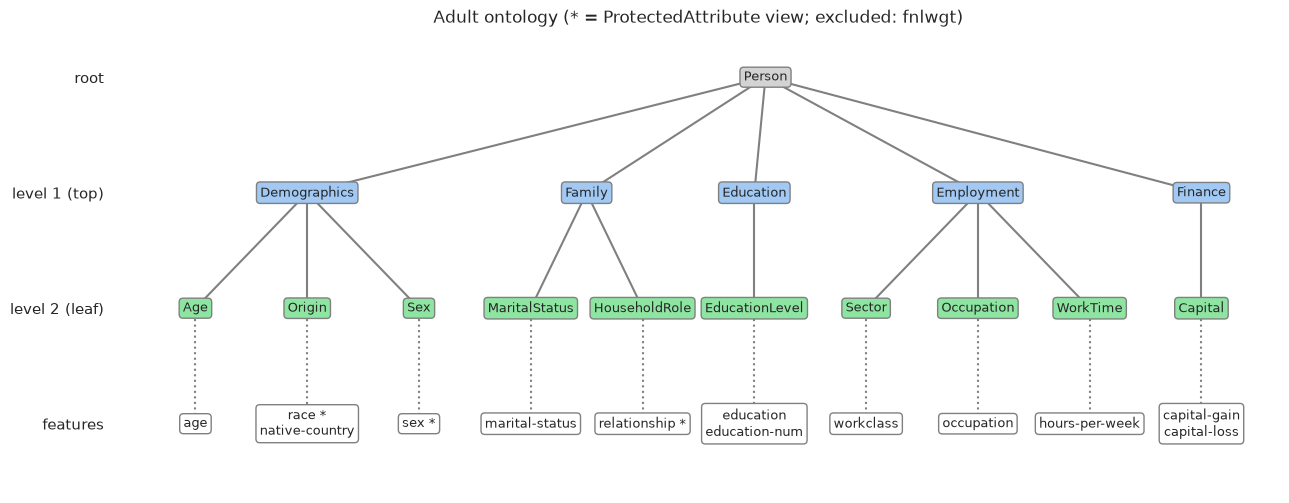

In [2]:
# Layout: one column per leaf, each top concept centred over its leaves, the root centred over the top concepts
leaves = [(top, leaf, feats) for top, ls in ontology.HIERARCHY.items() for leaf, feats in ls.items()]
fig, ax = plt.subplots(figsize=(15, 6))
y = {0: 3, 1: 2, 2: 1, 3: 0}
xs = {leaf: i for i, (_, leaf, _) in enumerate(leaves)}
tops = {top: sum(xs[l] for l in ls) / len(ls) for top, ls in ontology.HIERARCHY.items()}
root_x = sum(tops.values()) / len(tops)


def node(x, yy, text, color):
    ax.text(x, yy, text, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc=color, ec="grey"))


node(root_x, y[0], "Person", "lightgrey")
for top, x in tops.items():
    ax.plot([root_x, x], [y[0], y[1]], c="grey", zorder=0)
    node(x, y[1], top, sns.color_palette("pastel")[0])
for top, leaf, feats in leaves:
    x = xs[leaf]
    ax.plot([tops[top], x], [y[1], y[2]], c="grey", zorder=0)
    node(x, y[2], leaf, sns.color_palette("pastel")[2])
    # features under each leaf; * marks the ones also in the ProtectedAttribute view
    prot = [f for f in feats if ontology.is_protected(f)]
    label = "\n".join(f + (" *" if f in prot else "") for f in feats)
    ax.plot([x, x], [y[2], y[3]], c="grey", ls=":", zorder=0)
    node(x, y[3], label, "white")
ax.set(xlim=(-0.7, len(leaves) - 0.3), ylim=(-0.6, 3.4), yticks=list(y.values()),
       yticklabels=["root", "level 1 (top)", "level 2 (leaf)", "features"])
ax.tick_params(left=False)
ax.set_xticks([])
sns.despine(left=True, bottom=True)
ax.set_title(f"Adult ontology (* = ProtectedAttribute view; excluded: {', '.join(EXCLUDED)})");
plt.gcf().savefig(FIG / "ontology_hierarchy.png", dpi=200, bbox_inches="tight")

## 2. Feature coverage

Every encoded column inherits the concept of its source feature.

In [3]:
df = read()
X, y_, source = encode(df)
cov = pd.DataFrame({"column": list(source), "feature": list(source.values())})
cov["level2"] = cov["feature"].map(lambda f: ontology.concept_of(f, 2))
cov["level1"] = cov["feature"].map(lambda f: ontology.concept_of(f, 1))
cov["protected"] = cov["feature"].map(ontology.is_protected)

assert cov[["level1", "level2"]].notna().all().all(), "encoded column outside the ontology"
assert cov.groupby("feature")[["level1", "level2"]].nunique().eq(1).all().all()  # one concept per level
assert set(EXCLUDED).isdisjoint(cov["feature"])
assert ontology.concept_of("fnlwgt", 1) is None

print(len(cov), "encoded columns,", cov["feature"].nunique(), "features, all mapped")
(cov.groupby(["level1", "level2"])
    .agg(features=("feature", lambda s: ", ".join(dict.fromkeys(s))), columns=("column", "size"),
         protected_columns=("protected", "sum")))

104 encoded columns, 13 features, all mapped


features  columns  \
level1       level2                                                
Demographics Age                                    age        1   
             Origin                race, native-country       46   
             Sex                                    sex        2   
Education    EducationLevel    education-num, education       17   
Employment   Occupation                      occupation       14   
             Sector                           workclass        8   
             WorkTime                    hours-per-week        1   
Family       HouseholdRole                 relationship        6   
             MaritalStatus               marital-status        7   
Finance      Capital         capital-gain, capital-loss        2   

                             protected_columns  
level1       level2                             
Demographics Age                             0  
             Origin                          5  
             Sex                             2  
Education    EducationLevel                  0  
Employment   Occupation                      0  
             Sector                          0  
             WorkTime                        0  
Family       HouseholdRole                   6  
             MaritalStatus                   0  
Finance      Capital                         0

One-hot columns are uneven across concepts (`Origin` holds 46 columns from `native-country` and `race`,
`Age` one). Concept vectors (`04_concept_agreement.ipynb`) sum absolute contributions, so the column count does not by itself inflate a concept,
but trees can split on more distinct columns of large concepts.

## 3. Information content

Intrinsic IC as in TREPAN Reloaded: `IC(c) = 1 - log(sub-concepts(c) + 1) / log(N)`, with `N` = 16 concepts under `Person`.
Leaves are maximally specific (IC = 1), `Person` is 0. Reported only; not used for training.

In [4]:
ic = pd.DataFrame(
    [(c.name, c.is_a[0].name if c is not onto.Person else "-", len(c.descendants()) - 1, ontology.information_content(c.name))
     for c in onto.Person.descendants()],
    columns=["concept", "parent", "sub_concepts", "IC"],
).sort_values(["IC", "concept"])
ic

,concept,parent,sub_concepts,IC
0,Person,-,15,0.000000
8,Demographics,Person,3,0.500000
15,Employment,Person,3,0.500000
9,Family,Person,2,0.603759
1,Education,Person,1,0.750000
2,Finance,Person,1,0.750000
3,Age,Demographics,0,1.000000
12,Capital,Finance,0,1.000000
11,EducationLevel,Education,0,1.000000
10,HouseholdRole,Family,0,1.000000


Top concepts differ only by their number of leaves (Employment, Demographics: 3; Family: 2; Education, Finance: 1),
so IC ranks Education/Finance as more specific than Employment/Demographics even though all five are top-level.